In [1]:
from jhr.codes.espresso.io import QEOutParser
prs = QEOutParser('pw.x')
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/study/scf.out'
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out'
df = prs.outparser.Process(file)

/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out


In [14]:
import numpy as np
ucs = -126/2
ui = -757/2
upb = -3482/4
uzn = -923

u = np.array([ucs, upb, ui])
n = np.array([8, 8, 24])

e_bulk = -16564

(e_bulk - np.sum(u*n))/np.sum(n)*13.6



np.float64(-4.08)

## Defect Analysis (Test)

In [18]:
if True:
    import sys
    sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/")
    # ------------------------
    
    import warnings
    from monty.serialization import loadfn
    # from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
    from jhr.dev.defect.thermo import FormationEnergyDiagram
    from pymatgen.io.vasp import Vasprun
    
    warnings.filterwarnings("ignore")
    
    from pathlib import Path
    
    from pymatgen.analysis.defects.core import Substitution
    from pymatgen.core import PeriodicSite, Species, Structure
    
    directory = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files"
    #directory = "/home/fes33/Documents/Temp/Mg_Ga"
    
    TEST_FILES = Path(directory)


In [ ]:

gan_struct = Structure.from_file(TEST_FILES / "GaN.vasp")

# make a substitution site
ga_site = gan_struct[0]
mg_site = PeriodicSite(
    species=Species("Mg"), coords=ga_site.frac_coords, lattice=gan_struct.lattice
)

# instantiate the defect object
mg_ga = Substitution(structure=gan_struct, site=mg_site)

sc_dir = TEST_FILES / "Mg_Ga"
# ents = MPRester().get_entries_in_chemsys("Mg-Ga-N") # Query from MPRester
ents = loadfn(TEST_FILES / "Ga_Mg_N.json")  # Load from local

print(ents)
print("----")

fed = FormationEnergyDiagram.with_directories(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        0: sc_dir / "q=0",
        # -1: sc_dir / "q=-1",
        # 1: sc_dir / "q=1",
    },
    defect=mg_ga,
    pd_entries=ents,
    dielectric=10,
)

fed.as_dataframe()

In [ ]:


from pymatgen.analysis.defects.corrections.freysoldt import plot_plnr_avg
plot_data = fed.defect_entries[1].corrections_metadata["freysoldt"]["plot_data"]
plot_plnr_avg(plot_data[0], title="Lattice Direction 1")
plot_plnr_avg(plot_data[1], title="Lattice Direction 2")
plot_plnr_avg(plot_data[2], title="Lattice Direction 3")



## Defect Analysis

0.0

In [15]:
if 'imports':
    apikey = '4a3cEY6Q0G6DyR1BcQQ8UaDGK4JO3KFU'
    import sys
    import json
    #sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/")
    sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Cloned/pymatgen-analysis-defects")
    # ------------------------
    from pymatgen.core import Element
    from mp_api.client import MPRester
    from pymatgen.io.espresso.outputs import PWxml
    
    
    import warnings
    from monty.serialization import loadfn, dumpfn
    # from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
    from jhr.dev.defect.thermo import FormationEnergyDiagram
    from pymatgen.io.vasp import Vasprun
    
    warnings.filterwarnings("ignore")
    
    from pathlib import Path
    
    from pymatgen.analysis.defects.core import Substitution
    from pymatgen.core import PeriodicSite, Species, Structure
    
    #directory = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files"
    directory = "/home/fes33/Documents/Temp/"
    
    TEST_FILES = Path(directory)

pristine_file = '/home/fes33/Documents/Temp/Mg_Ga/bulk_sc/aiida.xml'
pristine_calc = PWxml(pristine_file)

pristine_struct = pristine_calc.structures[0]
site_num = 8

# make a substitution site
defect_site = pristine_struct[site_num]
defect_periodic = PeriodicSite(
    species=Species("Zn"), 
    coords=defect_site.frac_coords, 
    lattice=pristine_struct.lattice
)

# instantiate the defect object
defect = Substitution(structure=pristine_struct, site=defect_periodic)




d_ = {
   "energy": -4.08,
   "composition": pristine_struct.composition,
   "entry_id": "",
   "correction": 0, #pristine_calc.get_computed_entry(entry_id = "").correction
}
ent = ComputedEntry.from_dict(d_) #Computed entries list. Why twice?







sc_dir = TEST_FILES / "Mg_Ga"

download = True
if download: 
    with MPRester(apikey) as mpr:
        ents = mpr.get_entries_in_chemsys("Cs-Pb-I") # Query from MPRester
        dumpfn(ents, "ents.json", indent=2) 
else:
    ents = loadfn('ents.json')
    
# from pymatgen.entries.compatibility import MaterialsProjectCompatibility
# compat = MaterialsProjectCompatibility()
# ents = compat.process_entries(ents)

# required_elements = {Element("Cs"), Element("I"), Element("Pb")}
# # Filter entries
# ents = [
#     e for e in ents 
#     if (required_elements.issubset(set(e.composition.elements))) or 
#        len(set(e.composition.elements).intersection(required_elements)) == 1
# ]


#ents = loadfn(TEST_FILES / "Ga_Mg_N.json")  # Load from local
#ents = pristine_calc.get_computed_entry(entry_id = "")

fed = FormationEnergyDiagram.with_directoriesQE(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        # 0: sc_dir / "q=0",
        # -1: sc_dir / "q=-1",
        1: sc_dir / "q=1",
    },
    defect=defect,
    pd_entries=ents,
    dielectric=25,
    vbm = 0.3,
    bulk_stability = -1000

)
#fed.as_dataframe()

/home/fes33/miniforge3/envs/py313mats/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Retrieving ThermoDoc documents: 100%|██████| 58/58 [00:00<00:00, 1186681.13it/s]


BULK EN/ATOM:  -5634.293804313689
ENERGY -225371.75217254757
FORM EN -3.4708673129310337 Cs1 I1
FORM EN 0.0 I4
FORM EN -19.56570174172414 Cs4 I16
FORM EN 0.0 Pb1
FORM EN -11.052962109999996 Pb4 I8
FORM EN -17.86661232172414 Cs4 I12
FORM EN -9.960464596896543 Cs16 Pb36
FORM EN 0.0 Cs29
FROM ENERGY BULK -225298.311474251
-- Cs8 Pb8 I24 -225371.75217254757


ValueError: Bulk entry is not stable in the chemical potential diagram.Consider increasing the `bulk_stability` to make it more stable.

In [32]:

pristine_calc.final_energy = 0

AttributeError: property 'final_energy' of 'PWxml' object has no setter

In [12]:
from dataclasses import dataclass

@dataclass
class Example:
    x: int
    y: int

    def __post_init__(self):
        print(f"x = {self.x}, y = {self.y}")
Example(1,3)

x = 1, y = 3


Example(x=1, y=3)

In [13]:
fed.as_dataframe()

,name,charge_state,bulk_total_energy,defect_total_energy,correction_freysoldt
0,Zn_Pb,1,None,-219809.81058,0.031502


<Axes: title={'center': 'Lattice Direction 3'}, xlabel='distance along axis ($\\AA$)', ylabel='Potential (V)'>

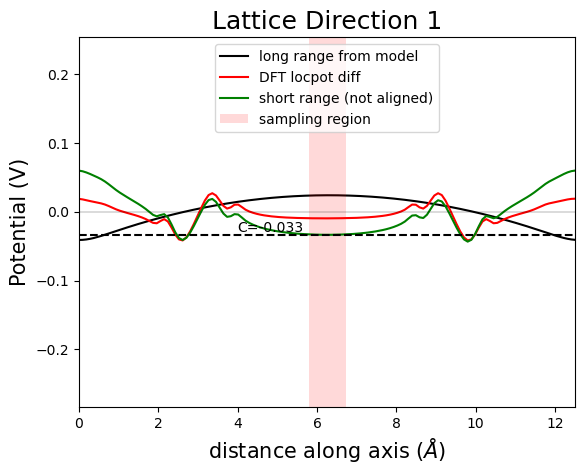

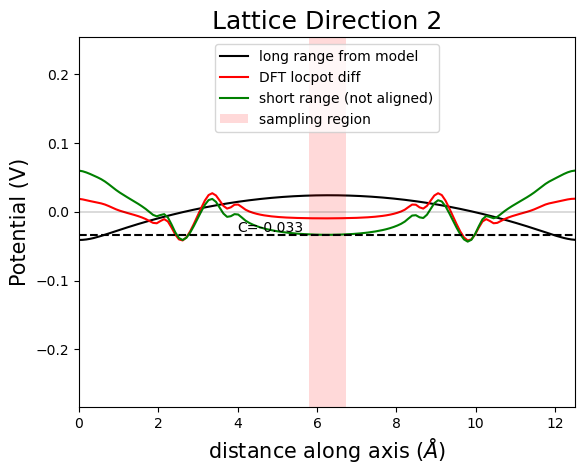

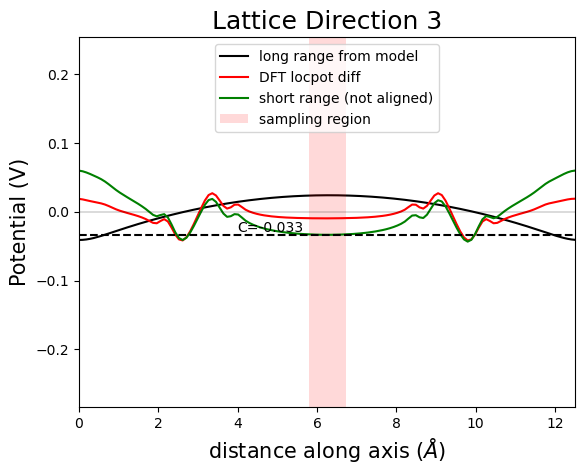

In [4]:


from pymatgen.analysis.defects.corrections.freysoldt import plot_plnr_avg
plot_data = fed.defect_entries[0].corrections_metadata["freysoldt"]["plot_data"]
plot_plnr_avg(plot_data[0], title="Lattice Direction 1")
plot_plnr_avg(plot_data[1], title="Lattice Direction 2")
plot_plnr_avg(plot_data[2], title="Lattice Direction 3")

In [14]:
from pymatgen.analysis.chempot_diagram import ChemicalPotentialDiagram
from pymatgen.core import Element
ents = loadfn("ents.json")
chempot = ChemicalPotentialDiagram(ents, 
                                   # limits = {Element("Cs"):[-5,5], 
                                   #           Element("Pb"):[-5,5],                                  
                                   #           Element("Zn"):[-5,5],
                                   #           Element("I"):[-5,5]},
                                   default_min_limit = -5636
                                  )


In [15]:
chempot.domains

{'CsPbI3': array([[-5636.        , -5636.        , -5633.15638219],
        [-5636.        , -5627.46914657, -5636.        ],
        [-5627.46914657, -5636.        , -5636.        ]])}

In [129]:
from scipy.spatial import ConvexHull, HalfspaceIntersection

hyperplanes = chempot._hyperplanes
border_hyperplanes = chempot._border_hyperplanes
entries = chempot._hyperplane_entries

hs_hyperplanes = np.vstack([hyperplanes, border_hyperplanes])
interior_point = np.min(chempot.lims, axis=1) + 1e-1
#interior_point = np.array([-1,-1,-1,-1])

hs_int = HalfspaceIntersection(hs_hyperplanes, interior_point)

domains: dict[str, list] = {entry.reduced_formula: [] for entry in entries}

for intersection, facet in zip(hs_int.intersections, hs_int.dual_facets, strict=True):
    for v in facet:
        if v < len(entries):
            this_entry = entries[v]
            formula = this_entry.reduced_formula
            domains[formula].append(intersection)

d = {k: np.array(v) for k, v in domains.items() if v}

QhullError: QH6023 qhull input error: feasible point is not clearly inside halfspace
feasible point:   -4.9   -4.9   -4.9   -4.9 
     halfspace:    0.2      0    0.2    0.6 
     at offset: 5632.457811856275  and distance: 5627.557811856276 
The halfspace was at index 0

While executing:  | qhull H 
Options selected for Qhull 2019.1.r 2019/06/21:
  run-id 904412569  Halfspace  _maxoutside  0


## class

In [138]:
from jhr._helpers import Constants
class PWParse:
    """
    From: https://blog.levilentz.com/parse-quantum-espresso-output-file/

    Takes a pw.x output file and reads all the relevant values.

    Example:
      test = PWParse()
      test.Process("vc.out")

      print(test.to_JSON())


    """


    def __init__(self, file = None):
        self.file = file
        self.BOHRtoA = Constants.BOHRtoA
        self.RYtoeV = Constants.RYtoeV
    def Process(self, file_path = None):
        """
        Parses a passed file for standard parsing. Uses self.file if no file is passed. 
        """
        if file_path is None: file_path = self.file

        cols = ["value", "unit", "description"]
        self.data = pd.DataFrame(columns=cols)
        self.lattice = {"a": [0, 0, 0], "b": [0, 0, 0], "c": [0, 0, 0]}
        self.norms = {}
        self.angles = {}
        self.atoms = []
        
        print(file_path)
        f = open(file_path, "r")

        for linenum, i in enumerate(f):
            if linenum < 1000:
                if "number of k points=" in i:
                    val = 8
                    self.data.loc["kpoints"] = [val, "unitless", "Number of k-points in the Brillouin zone"]
                    continue
            if "End of self-consistent calculation" in i:
                bands = 8
                kpts = 74
                
                numlines = int(np.floor(bands / 8.0)) + 1

                bnddiagram = np.zeros((kpts, bands),dtype=float)
                counter = 0
                while counter < kpts:
                    line = next(f)
                    if "k =" in line:
                        line = next(f)
                        idx = 0
                        for _ in range(numlines):
                            line = next(f).split()
                            for val in line:
                                bnddiagram[counter][idx] = float(val)
                                idx += 1
                        counter += 1
                bnddiagram = np.random.rand(74,
                self.data.loc["bnddiagram"] = [bnddiagram, "N/A", "Band diagram"]
                continue

        f.close()
        return self.data


## code

In [ ]:
"""Classes and methods related to thermodynamics and energy."""

from __future__ import annotations

from monty.serialization import dumpfn

import collections
import logging
from dataclasses import dataclass, field
from itertools import chain, groupby
from pathlib import Path
from typing import TYPE_CHECKING, Any, Callable

import numpy as np
from matplotlib import pyplot as plt
from monty.dev import deprecated
from monty.json import MSONable
from pymatgen.analysis.chempot_diagram import ChemicalPotentialDiagram
from pymatgen.analysis.defects.core import Defect, NamedDefect
from pymatgen.analysis.defects.corrections.freysoldt import get_freysoldt_correction
from pymatgen.analysis.defects.finder import DefectSiteFinder
from pymatgen.analysis.defects.supercells import get_closest_sc_mat
from pymatgen.analysis.defects.utils import get_zfile, group_docs
from pymatgen.analysis.phase_diagram import PhaseDiagram
from pymatgen.analysis.structure_matcher import ElementComparator, StructureMatcher
from pymatgen.core import Composition, Element
from pymatgen.electronic_structure.dos import FermiDos
from pymatgen.entries.computed_entries import ComputedEntry
from pymatgen.io.vasp import Locpot, Vasprun, VolumetricData
from pyrho.charge_density import get_volumetric_like_sc
from scipy.constants import value as _cd
from scipy.optimize import bisect
from scipy.spatial import ConvexHull

from pymatgen.io.espresso.outputs import PWxml


if TYPE_CHECKING:
    from collections.abc import Generator, Sequence

    from matplotlib.axes import Axes
    from numpy.typing import ArrayLike, NDArray
    from pandas import DataFrame
    from pymatgen.analysis.defects.utils import CorrectionResult
    from pymatgen.core import Structure
    from pymatgen.electronic_structure.dos import Dos
    from pymatgen.entries.computed_entries import ComputedStructureEntry

__author__ = "Jimmy-Xuan Shen, Danny Broberg, Shyam Dwaraknath"
__copyright__ = "Copyright 2022, The Materials Project"
__maintainer__ = "Jimmy-Xuan Shen"
__email__ = "jmmshn@gmail.com"

_logger = logging.getLogger(__name__)
boltzman_eV_K = _cd("Boltzmann constant in eV/K")


@dataclass
class DefectEntry(MSONable):
    """Data for completed defect supercell calculation.

    Attributes:
        defect:
            The defect object used to generate the supercell.
        charge_state:
            The charge state of the defect.
        sc_entry:
            The ComputedStructureEntry for the supercell.
        sc_defect_frac_coords:
            The fractional coordinates of the defect in the supercell.
            If None, structures attributes of the locpot file will be used to
            automatically determine the defect location.
        bulk_entry:
            The ComputedEntry for the bulk material. If this is provided, the energy difference
            can be calculated from this automatically. The `bulk_entry` can also be provided as
            an attribute of the `DefectEntry` object. If both are provided, the one for
            `FormationEnergyDiagram` has precedence.
        corrections:
            A dictionary of corrections to the energy.
        corrections_metadata:
            A dictionary that acts as a generic container for storing information
            about how the corrections were calculated.  These should are only used
            for debugging and plotting purposes.
            PLEASE DO NOT USE THIS AS A CONTAINER FOR IMPORTANT DATA.
        entry_id:
            The entry_id for the defect entry. Usually the same as the entry_id of the
            defect supercell entry.
    """

    defect: Defect
    charge_state: int
    sc_entry: ComputedStructureEntry
    corrections: dict[str, float] = field(default_factory=dict)
    corrections_metadata: dict[str, Any] = field(default_factory=dict)
    sc_defect_frac_coords: tuple[float, float, float] | None = None
    bulk_entry: ComputedEntry | None = None
    entry_id: str | None = None

    def __post_init__(self) -> None:
        """Post-initialization."""
        self.charge_state = int(self.charge_state)
        self.entry_id = self.entry_id or self.sc_entry.entry_id

    def get_freysoldt_correction(
        self,
        defect_locpot: Locpot | dict,
        bulk_locpot: Locpot | dict,
        dielectric: float | NDArray,
        defect_struct: Structure | None = None,
        bulk_struct: Structure | None = None,
        **kwargs,
    ) -> CorrectionResult:
        """Calculate the Freysoldt correction.

        Updates the corrections dictionary with the Freysoldt correction
        and returns the planar averaged potential data for plotting.

        Args:
            defect_locpot:
                The Locpot object for the defect supercell.
                Or a dictionary of the planar averaged locpot
            bulk_locpot:
                The Locpot object for the bulk supercell.
                Or a dictionary of the planar averaged locpot
            dielectric:
                The dielectric tensor or constant for the bulk material.
            defect_struct:
                The defect structure. If None, the structure of the defect_locpot
                will be used.
            bulk_struct:
                The bulk structure. If None, the structure of the bulk_locpot
                will be used.
            **kwargs:
                Additional keyword arguments for the get_correction method.

        Returns:
            dict:
                The plotting data to analyze the planar averaged electrostatic potential
                in the three periodic lattice directions.
        """
        if defect_struct is None:
            defect_struct = getattr(defect_locpot, "structure", None)
        if bulk_struct is None:
            bulk_struct = getattr(bulk_locpot, "structure", None)

        if defect_struct is None or bulk_struct is None:  # pragma: no cover
            msg = "defect_struct and/or bulk_struct is missing either provide the structure or provide the complete locpot."
            raise ValueError(
                msg,
            )

        if self.sc_defect_frac_coords is None:
            finder = DefectSiteFinder()
            defect_fpos = finder.get_defect_fpos(
                defect_structure=defect_struct,
                base_structure=bulk_struct,
            )
            self.sc_defect_frac_coords = defect_fpos
        else:  # pragma: no cover
            defect_fpos = self.sc_defect_frac_coords

        if isinstance(defect_locpot, VolumetricData):
            defect_gn = defect_locpot.dim
        elif isinstance(defect_locpot, dict):
            defect_gn = tuple(map(len, (defect_locpot for k in ["0", "1", "2"])))

        if isinstance(bulk_locpot, VolumetricData):
            bulk_sc_locpot = get_sc_locpot(
                uc_locpot=bulk_locpot,
                defect_struct=defect_struct,
                grid_out=defect_gn,
                up_sample=2,
            )
            bulk_locpot = bulk_sc_locpot
        frey_corr = get_freysoldt_correction(
            q=self.charge_state,
            dielectric=dielectric,
            defect_locpot=defect_locpot,
            bulk_locpot=bulk_sc_locpot,
            defect_frac_coords=defect_fpos,
            lattice=defect_struct.lattice,
            **kwargs,
        )
        self.corrections.update(
            {
                "freysoldt": frey_corr.correction_energy,
            },
        )
        self.corrections_metadata.update({"freysoldt": frey_corr.metadata.copy()})
        return frey_corr

    @property
    def corrected_energy(self) -> float:
        """The energy of the defect entry with all corrections applied."""
        return self.sc_entry.energy + sum(self.corrections.values())

    def get_ediff(self) -> float | None:
        """Get the energy difference between the defect and the bulk (including finite-size correction)."""
        if self.bulk_entry is None:
            msg = (
                "Attempting to compute the energy difference without a bulk entry data."
            )
            raise RuntimeError(
                msg,
            )
        return self.corrected_energy - self.bulk_entry.energy

    def get_summary_dict(self) -> dict:
        """Get a summary dictionary for the defect entry."""
        corrections_d = {f"correction_{k}": v for k, v in self.corrections.items()}
        res = {
            "name": self.defect.name,
            "charge_state": self.charge_state,
            "bulk_total_energy": self.bulk_entry.energy if self.bulk_entry else None,
            "defect_total_energy": self.sc_entry.energy,
        }
        res.update(corrections_d)
        return res

    @property
    def defect_chemsys(self) -> str:
        """Get the chemical system of the defect."""
        return "-".join(
            sorted({el.symbol for el in self.defect.defect_structure.elements})
        )



In [ ]:

@dataclass
class FormationEnergyDiagram(MSONable):
    """Formation energy.

    Attributes:
        defect_entries:
            The list of defect entries for the different charge states.
            The finite-size correction should already be applied to these.
        pd_entries:
            The list of entries used to construct the phase diagram and chemical
            potential diagram. They will be used to determine the stability region
            of the bulk crystal.  The entries are used instead of the ``PhaseDiagram``
            object to make serializing the object easier.
        vbm:
            The VBM of the bulk crystal.
        band_gap:
            The band gap of the bulk crystal.
        bulk_entry:
            The bulk computed entry to get the total energy of the bulk supercell.
            This is only used in case where the bulk entry data is not provided by
            the individual defect entries themselves. Default is None.
            The data from the `bulk_entry` attached to each `defect_entry` will be
            preferentially used if it is available.
        inc_inf_values:
            If False these boundary points at infinity are ignored when we look at the
            chemical potential limits.
            The stability region is sometimes unbounded, example:
            Mn_Ga in GaN, the chemical potential of Mn is does not affect
            the stability of GaN so it can go to ``-inf``.
            A artificial value is needed to help the half-space intersection algorithm.
            This can be justified since these tend to be the substitutional elements
            which should not have very negative chemical potential.
        bulk_stability:
            If the bulk energy is above the convex hull, lower it to this value below
            the convex hull.
    """

    defect_entries: list[DefectEntry]
    pd_entries: list[ComputedEntry]
    vbm: float
    band_gap: float | None = None
    bulk_entry: ComputedStructureEntry | None = None
    inc_inf_values: bool = False
    bulk_stability: float = 0.001

    def __post_init__(self) -> None:
        """Post-initialization.

        - Reconstruct the phase diagram with the bulk entry
        - Make sure that the bulk entry is stable
        - create the chemical potential diagram using only the formation energies
        """
        g = group_defect_entries(self.defect_entries)
        if next(g, True) and next(g, False):
            msg = (
                "Defects are not of same type! "
                "Use MultiFormationEnergyDiagram for multiple defect types"
            )
            raise ValueError(
                msg,
            )
        # if all of the `DefectEntry` objects have the same `bulk_entry` then `self.bulk_entry` is not needed
        if self.bulk_entry is None and any(
            x.bulk_entry is None for x in self.defect_entries
        ):
            msg = "The bulk entry must be provided."
            raise RuntimeError(
                msg,
            )

        bulk_entry = self.bulk_entry or min(
            [x.bulk_entry for x in self.defect_entries],
            key=lambda x: x.energy_per_atom,
        )

        pd_ = PhaseDiagram(self.pd_entries)
        entries = pd_.stable_entries | {bulk_entry}

        
        
        pd_ = PhaseDiagram(entries)

        self.phase_diagram = ensure_stable_bulk(pd_, bulk_entry, self.bulk_stability)
        entries = []
        for entry in self.phase_diagram.stable_entries:
            d_ = {
                "energy": self.phase_diagram.get_form_energy(entry),
                "composition": entry.composition,
                "entry_id": entry.entry_id,
                "correction": 0.0,
            }
            entries.append(ComputedEntry.from_dict(d_))
            entries.append(ComputedEntry.from_dict(d_))

        self.chempot_diagram = ChemicalPotentialDiagram(entries)

        if bulk_entry.composition.reduced_formula in self.chempot_diagram.domains:  
          print("TRUE")
        
        if (
            bulk_entry.composition.reduced_formula not in self.chempot_diagram.domains
        ):  # pragma: no cover
            msg = (
                "Bulk entry is not stable in the chemical potential diagram."
                "Consider increasing the `bulk_stability` to make it more stable."
            )
            raise ValueError(
                msg,
            )
        chempot_limits = self.chempot_diagram.domains[
            bulk_entry.composition.reduced_formula
        ]

        if self.inc_inf_values:
            self._chempot_limits_arr = chempot_limits
        else:
            boundary_value = self.chempot_diagram.default_min_limit
            self._chempot_limits_arr = chempot_limits[
                ~np.any(chempot_limits == boundary_value, axis=1)
            ]

        self.dft_energies = {
            el: self.phase_diagram.get_hull_energy_per_atom(Composition(str(el)))
            for el in self.phase_diagram.elements
        }

    @classmethod
    def with_atomic_entries(
        cls,
        defect_entries: list[DefectEntry],
        atomic_entries: list[ComputedEntry],
        phase_diagram: PhaseDiagram,
        vbm: float,
        bulk_entry: ComputedEntry | None = None,
        **kwargs,
    ) -> FormationEnergyDiagram:
        """Create a FormationEnergyDiagram object using an existing phase diagram.

        Since the Formation energy usually looks like:

        E[Defect] - (E[Bulk] + ∑ E[Atom_i] + ∑ Chempot[Atom_i])

        The most convenient, and likely most accurate way to obtain the chemical potentials
        is to calculate the defect supercells and the atomic phases with the same level of theory.
        As long as the atomic phase energies are computed using the same settings as
        the defect supercell calculations, the method used to determine the enthalpy of
        formation of the different competing phases is not important.
        Then use the an experimentally corrected ``PhaseDiagram`` object (like the ones you can
        obtain from the Materials Project) to calculate the enthalpy of formation.

        Args:
            defect_entries:
                The list of defect entries for the different charge states.
                The finite-size correction should already be applied to these.
            atomic_entries:
                The list of entries used to construct the phase diagram and chemical
                potential diagram. They will be used to determine the stability region
                of the bulk crystal.
            phase_diagram:
                A separately computed phase diagram.
            vbm:
                The VBM of the bulk crystal.
            bulk_entry:
                The bulk computed entry to get the total energy of the bulk supercell.
            band_gap:
                The band gap of the bulk crystal. Passed directly to the \
                FormationEnergyDiagram constructor.
            inc_inf_values:
                If False these boundary points at infinity are ignored when we look at
                the chemical potential limits.
            **kwargs:
                Additional keyword arguments for the FormationEnergyDiagram class.

        Returns:
            FormationEnergyDiagram:
                The FormationEnergyDiagram object.
        """
        adjusted_entries = _get_adjusted_pd_entries(
            phase_diagram=phase_diagram,
            atomic_entries=atomic_entries,
        )
        return cls(
            bulk_entry=bulk_entry,
            defect_entries=defect_entries,
            pd_entries=adjusted_entries,
            vbm=vbm,
            **kwargs,
        )

    @classmethod
    def with_directoriesQE(
        cls,
        directory_map: dict[str, str | Path],
        defect: Defect,
        pd_entries: list[ComputedEntry],
        dielectric: float | NDArray,
        vbm: float | None = None,
        **kwargs,
    ) -> FormationEnergyDiagram:
        """Create a FormationEnergyDiagram from VASP directories.

        Args:
            directory_map: A dictionary mapping the defect name to the directory containing the
                VASP calculation.
            defect: The defect used to create the defect entries.
            pd_entries: The list of entries used to construct the phase diagram and chemical
                potential diagram. They will be used to determine the stability region
                of the bulk crystal.
            dielectric: The dielectric constant of the bulk crystal.
            vbm: The VBM of the bulk crystal.
            **kwargs: Additional keyword arguments for the constructor.
        """
        def get_file(directory: str | Path, ends_with: str = '.cube') -> Path:
            """
            Returns the first file in the directory that ends with the given suffix.
            
            Parameters:
                directory (str | Path): The directory to search in.
                ends_with (str): The file suffix to look for (default: '.cube').
            Returns:
                Path: Path to the first matching file.
            Raises:
                FileNotFoundError: If no matching file is found.
            """
            directory = Path(directory)
            for file in directory.iterdir():
                if file.is_file() and file.name.lower().endswith(ends_with.lower()):
                    return file

            msg = f"Could not find a file ending with '{ends_with}' in '{directory}'."
            raise FileNotFoundError(msg)
            return


        def _read_dir(directory: str | Path) -> tuple[ComputedEntry, Locpot]:
            #IMPELEMENT FOR QE
            directory = Path(directory)
            vr = PWxml(get_file(directory, ".xml"))
            ent = vr.get_computed_entry(entry_id = "")
            #locpot = Locpot.from_file(get_cubefile(directory, "cube"))
            locpot = VolumetricData.from_cube(get_file(directory, "cube"))
            print(locpot)
            return ent, locpot

        if "bulk" not in directory_map:
            msg = "The bulk directory must be provided."
            raise ValueError(msg)
        bulk_entry, bulk_locpot = _read_dir(directory_map["bulk"])

        def_entries = []
        for qq, q_dir in directory_map.items():
            if qq == "bulk":
                continue
            q_entry, q_locpot = _read_dir(q_dir)
            q_d_entry = DefectEntry(
                defect=defect,
                charge_state=int(qq),
                sc_entry=q_entry,
            )

            q_d_entry.get_freysoldt_correction(
                defect_locpot=q_locpot,
                bulk_locpot=bulk_locpot,
                dielectric=dielectric,
            )
            def_entries.append(q_d_entry)
        if vbm is None:
#            vr = Vasprun(get_zfile(Path(directory_map["bulk"]), "vasprun.xml"))
#            vbm = vr.get_band_structure().get_vbm()["energy"]
             vr = PWxml(get_file(directory_map["bulk"], ".xml"))
             vbm = vr.vbm
             print(vbm)
        return cls(
            bulk_entry=bulk_entry,
            defect_entries=def_entries,
            pd_entries=pd_entries,
            vbm=vbm,
            **kwargs,
        )



    @classmethod
    def with_directories(
        cls,
        directory_map: dict[str, str | Path],
        defect: Defect,
        pd_entries: list[ComputedEntry],
        dielectric: float | NDArray,
        vbm: float | None = None,
        **kwargs,
    ) -> FormationEnergyDiagram:
        """Create a FormationEnergyDiagram from VASP directories.

        Args:
            directory_map: A dictionary mapping the defect name to the directory containing the
                VASP calculation.
            defect: The defect used to create the defect entries.
            pd_entries: The list of entries used to construct the phase diagram and chemical
                potential diagram. They will be used to determine the stability region
                of the bulk crystal.
            dielectric: The dielectric constant of the bulk crystal.
            vbm: The VBM of the bulk crystal.
            **kwargs: Additional keyword arguments for the constructor.
        """

        def _read_dir(directory: str | Path) -> tuple[ComputedEntry, Locpot]:
            directory = Path(directory)
            vr = Vasprun(get_zfile(Path(directory), "vasprun.xml"))
            ent = vr.get_computed_entry()
            locpot = Locpot.from_file(get_zfile(directory, "LOCPOT"))
            return ent, locpot

        if "bulk" not in directory_map:
            msg = "The bulk directory must be provided."
            raise ValueError(msg)
        bulk_entry, bulk_locpot = _read_dir(directory_map["bulk"])

        def_entries = []
        for qq, q_dir in directory_map.items():
            if qq == "bulk":
                continue
            q_entry, q_locpot = _read_dir(q_dir)
            q_d_entry = DefectEntry(
                defect=defect,
                charge_state=int(qq),
                sc_entry=q_entry,
            )

            q_d_entry.get_freysoldt_correction(
                defect_locpot=q_locpot,
                bulk_locpot=bulk_locpot,
                dielectric=dielectric,
            )
            def_entries.append(q_d_entry)
        if vbm is None:
            vr = Vasprun(get_zfile(Path(directory_map["bulk"]), "vasprun.xml"))
            vbm = vr.get_band_structure().get_vbm()["energy"]

        return cls(
            bulk_entry=bulk_entry,
            defect_entries=def_entries,
            pd_entries=pd_entries,
            vbm=vbm,
            **kwargs,
        )

    def _parse_chempots(self, chempots: dict) -> dict:
        """Parse the chemical potentials.

        Make sure that the chemical potential is represented as a dictionary.
            { Element: float }

        Args:
            chempots:
                A dictionary or list of chemical potentials.
                If a list, use the element order from self.chempot_diagram.elements.

        Returns:
            dict:
                A dictionary of chemical potentials.
        """
        if not isinstance(chempots, dict):
            chempots = {
                el: chempots[i] for i, el in enumerate(self.chempot_diagram.elements)
            }
        return chempots

    def _vbm_formation_energy(self, defect_entry: DefectEntry, chempots: dict) -> float:
        """Compute the formation energy at the VBM.

        Compute the formation energy at the VBM (essentially the y-intercept)
        for a given defect entry and set of chemical potentials.
        If the `bulk_entry` attribute is set, this will be used
        difference will be computed using that value.

        Args:
            defect_entry:
                The defect entry for which the formation energy is computed.
            chempots:
                A dictionary of chemical potentials for each element.

        Returns:
            float:
                The formation energy at the VBM.
        """
        chempots = self._parse_chempots(chempots)
        en_change = sum(
            [
                (self.dft_energies[Element(el)] + chempots[Element(el)]) * fac
                for el, fac in defect_entry.defect.element_changes.items()
            ],
        )

        try:
            ediff = defect_entry.get_ediff()
        except RuntimeError:
            ediff = defect_entry.corrected_energy - self.bulk_entry.energy

        return ediff - en_change + self.vbm * defect_entry.charge_state

    @property
    def chempot_limits(self) -> list[dict[Element, float]]:
        """Return the chemical potential limits in dictionary format."""
        return [
            dict(zip(self.chempot_diagram.elements, vertex))
            for vertex in self._chempot_limits_arr
        ]

    @property
    def competing_phases(self) -> list[dict[str, ComputedEntry]]:
        """Return the competing phases."""
        bulk_formula = self.bulk_entry.composition.reduced_formula
        cd = self.chempot_diagram
        res = []
        for pt in self._chempot_limits_arr:
            competing_phases = {}
            for hp_ent, hp in zip(cd._hyperplane_entries, cd._hyperplanes):
                if hp_ent.composition.reduced_formula == bulk_formula:
                    continue
                if _is_on_hyperplane(pt, hp):
                    competing_phases[hp_ent.composition.reduced_formula] = hp_ent
            res.append(competing_phases)
        return res

    @property
    def bulk_formula(self) -> str:
        """Get the bulk formula."""
        return self.defect_entries[0].defect.structure.composition.reduced_formula

    @property
    def defect(self) -> Defect:
        """Get the defect that this FormationEnergyDiagram represents."""
        return self.defect_entries[0].defect

    @property
    def defect_chemsys(self) -> str:
        """Get the chemical system of the defect."""
        return self.defect_entries[0].defect_chemsys

    def _get_lines(self, chempots: dict) -> list[tuple[float, float]]:
        """Get the lines for the formation energy diagram.

        Args:
            chempots:
                A dictionary of the chemical potentials (referenced to the elements)
                representations a vertex of the stability region of the chemical
                potential diagram.

        Returns:
            list[tuple[float, float]]:
                List of the slope and intercept of the lines for the formation
                energy diagram.
        """
        chempots = self._parse_chempots(chempots)
        lines = []
        for def_ent in self.defect_entries:
            b = self._vbm_formation_energy(def_ent, chempots)
            m = float(def_ent.charge_state)
            lines.append((m, b))
        return lines

    def get_transitions(
        self,
        chempots: dict,
        x_min: float = 0,
        x_max: float | None = None,
    ) -> list[tuple[float, float]]:
        """Get the transition levels for the formation energy diagram.

        Get all of the kinks in the formation energy diagram.
        The points at the VBM and CBM are given by the first and last
        point respectively.

        Args:
            chempots:
                A dictionary of the chemical potentials (referenced to the elements)
                representations a vertex of the stability region of the chemical
                potential diagram.
            x_min:
                The minimum x value (Energy) for the transition levels.
            x_max:
                The maximum x value (Energy) for the transition levels. If None, the band gap is used.

        Returns:
            Transition levels and the formation energy at each transition level.
            The first and last points are the intercepts with the
            VBM and CBM respectively.
        """
        chempots = self._parse_chempots(chempots)
        if x_max is None:  # pragma: no cover
            x_max = self.band_gap

        lines = self._get_lines(chempots)
        lines = get_lower_envelope(lines)
        return get_transitions(lines, x_min, x_max)

    def get_formation_energy(self, fermi_level: float, chempot_dict: dict) -> float:
        """Get the formation energy at a given Fermi level.

        Linearly interpolate between the transition levels.

        Args:
            fermi_level:
                The Fermi level at which the formation energy is computed.
            chempot_dict:
                A dictionary of the chemical potentials (referenced to the elemental energies).

        Returns:
            The formation energy at the given Fermi level.
        """
        transitions = np.array(
            self.get_transitions(chempot_dict, x_min=-100, x_max=100),
        )
        # linearly interpolate between the set of points
        return np.interp(fermi_level, transitions[:, 0], transitions[:, 1])

    def get_concentration(
        self,
        fermi_level: float,
        chempots: dict,
        temperature: float,
    ) -> float:
        """Get equilibrium defect concentration assuming the dilute limit.

        Args:
            fermi_level: fermi level with respect to the VBM
            chempots: Chemical potentials
            temperature: in Kelvin
        """
        chempots = self._parse_chempots(chempots=chempots)
        fe = self.get_formation_energy(fermi_level, chempots)
        return self.defect_entries[0].defect.multiplicity * fermi_dirac(
            energy=fe,
            temperature=temperature,
        )

    def as_dataframe(self) -> DataFrame:
        """Return the formation energy diagram as a pandas dataframe."""
        from pandas import DataFrame

        defect_entries = self.defect_entries
        l_ = (x.get_summary_dict() for x in defect_entries)
        return DataFrame(l_)

    def get_chempots(self, rich_element: Element | str, en_tol: float = 0.01) -> dict:
        """Get the chemical potential for a desired growth condition.

        Choose an element to be rich in, require the chemical potential of that element
        to be near the MAX energy among the points (MAX_EN - en_tol, MAX_EN), then sort
        the remaining elements by:
            1. Are they in the bulk structure:
                elements in the bulk structure are prioritized.
            2. how similar they in electron affinity to the rich element:
                dis-similar elements are prioritized.

        .. note::
            Priority 2 is pretty arbitrary, but it is a good starting point.


        Based on that priority list, take the minimum chemical potential extrema.

        Args:
            rich_element: The element that are rich in the growth condition.
            en_tol: Energy tolerance for the chemical potential of the rich element.

        Returns:
            A dictionary of the chemical potentials for the growth condition.
        """
        rich_element = Element(rich_element)
        max_val = max(self.chempot_limits, key=lambda x: x[rich_element])[rich_element]
        rich_conditions = list(
            filter(
                lambda cp: abs(cp[rich_element] - max_val) < en_tol,
                self.chempot_limits,
            ),
        )
        if len(rich_conditions) == 0:  # pragma: no cover
            msg = f"Cannot find a chemical potential condition with {rich_element} near zero."
            raise ValueError(
                msg,
            )
        # defect = self.defect_entries[0].defect
        in_bulk = self.defect_entries[0].sc_entry.composition.elements
        # make sure they are of type Element
        in_bulk = [Element(x.symbol) for x in in_bulk]
        not_in_bulk = list(set(self.chempot_limits[0].keys()) - set(in_bulk))
        in_bulk = list(filter(lambda x: x != rich_element, in_bulk))

        def el_sorter(element: Element) -> float:
            return -abs(element.electron_affinity - rich_element.electron_affinity)

        el_list = sorted(in_bulk, key=el_sorter) + sorted(not_in_bulk, key=el_sorter)

        def chempot_sorter(chempot_dict: dict) -> tuple[float, ...]:
            return tuple(chempot_dict[el] for el in el_list)

        return min(rich_conditions, key=chempot_sorter)

    def __repr__(self) -> str:
        """Representation."""
        defect_entry_summary = [
            f"\t{dent.defect.name} {dent.charge_state} {dent.corrected_energy}"
            for dent in self.defect_entries
        ]

        txt = (
            f"{self.__class__.__name__} for {self.defect.name}",
            "Defect Entries:",
            "\n".join(defect_entry_summary),
        )
        return "\n".join(txt)


@dataclass
class MultiFormationEnergyDiagram(MSONable):
    """Container for multiple formation energy diagrams."""

    formation_energy_diagrams: list[FormationEnergyDiagram]

    def __post_init__(self) -> None:
        """Set some attributes after initialization."""
        self.band_gap = self.formation_energy_diagrams[0].band_gap
        self.vbm = self.formation_energy_diagrams[0].vbm

    @classmethod
    def with_atomic_entries(
        cls,
        bulk_entry: ComputedEntry,
        defect_entries: list[DefectEntry],
        atomic_entries: list[ComputedEntry],
        phase_diagram: PhaseDiagram,
        vbm: float,
        **kwargs,
    ) -> MultiFormationEnergyDiagram:
        """Initialize using atomic entries.

        Initializes by grouping defect types, and creating a list of single
        FormationEnergyDiagram using the with_atomic_entries method (see above)

        Args:
            bulk_entry: bulk entry
            defect_entries: list of defect entries
            atomic_entries: list of atomic entries
            phase_diagram: phase diagram
            vbm: valence band maximum for the bulk phase
            **kwargs: additional kwargs for FormationEnergyDiagram
        """
        single_form_en_diagrams = []
        for _, defect_group in group_defect_entries(defect_entries=defect_entries):
            _fd = FormationEnergyDiagram.with_atomic_entries(
                bulk_entry=bulk_entry,
                defect_entries=defect_group,
                atomic_entries=atomic_entries,
                phase_diagram=phase_diagram,
                vbm=vbm,
                **kwargs,
            )
            single_form_en_diagrams.append(_fd)

        return cls(formation_energy_diagrams=single_form_en_diagrams)

    def solve_for_fermi_level(
        self,
        chempots: dict,
        temperature: float,
        dos: Dos,
    ) -> float:
        """Solves for the equilibrium fermi level at a given chempot, temperature, density of states.

        Args:
            chempots: dictionary of chemical potentials to use
            temperature: temperature at which to evaluate.
            dos: Density of states object. Must contain a structure attribute. If band_gap attribute
                is set, then dos band edges be shifted to match it.

        Returns:
            Equilibrium fermi level with respect to the valence band edge.
        """
        fdos = FermiDos(dos, bandgap=self.band_gap)
        bulk_factor = self.formation_energy_diagrams[
            0
        ].defect.structure.composition.get_reduced_formula_and_factor()[1]
        fdos_factor = fdos.structure.composition.get_reduced_formula_and_factor()[1]
        fdos_multiplicity = fdos_factor / bulk_factor
        fdos_cbm, fdos_vbm = fdos.get_cbm_vbm()

        def _get_chg(fd: FormationEnergyDiagram, ef: float) -> float:
            lines = fd._get_lines(chempots=chempots)
            return sum(
                fd.defect.multiplicity
                * charge
                * fermi_dirac(vbm_fe + charge * ef, temperature)
                for charge, vbm_fe in lines
            )

        def _get_total_q(ef: float) -> float:
            qd_tot = sum(
                _get_chg(fd=fd, ef=ef) for fd in self.formation_energy_diagrams
            )
            qd_tot += fdos_multiplicity * fdos.get_doping(
                fermi_level=ef + fdos_vbm,
                temperature=temperature,
            )
            return qd_tot

        return bisect(_get_total_q, -1.0, fdos_cbm - fdos_vbm + 1.0)


def group_defect_entries(
    defect_entries: list[DefectEntry],
    sm: StructureMatcher = None,
) -> Generator[tuple[str, list[DefectEntry]], None, None]:
    """Group defect entries by their representation.

    First by name then by structure.

    Args:
        defect_entries: list of defect entries
        sm: StructureMatcher to use for grouping

    Returns:
        Generator of (name, list of defect entries) tuples
    """
    if sm is None:
        sm = StructureMatcher(comparator=ElementComparator())

    def _get_structure(entry: DefectEntry) -> Structure:
        return entry.defect.defect_structure

    def _get_name(entry: DefectEntry) -> str:
        return entry.defect.name

    def _get_hash_no_structure(entry: DefectEntry) -> tuple[str, str]:
        return entry.defect.bulk_formula, entry.defect.name

    if all(isinstance(entry.defect, Defect) for entry in defect_entries):
        ent_groups = group_docs(
            defect_entries,
            sm=sm,
            get_structure=_get_structure,
            get_hash=_get_name,
        )
        yield from ent_groups
    elif all(isinstance(entry.defect, NamedDefect) for entry in defect_entries):
        l_ = sorted(defect_entries, key=_get_hash_no_structure)
        for _, g_entries_no_struct in groupby(l_, key=_get_hash_no_structure):
            similar_ents = list(g_entries_no_struct)
            yield similar_ents[0].defect.name, similar_ents


## GPT

In [17]:
from pymatgen.core import Structure
from pymatgen.entries.computed_entries import ComputedEntry
from pymatgen.ext.matproj import MPRester
from pymatgen.analysis.phase_diagram import PhaseDiagram
from pymatgen.analysis.defects.core import Substitution
#from jhr.analysis.defects.thermo import DefectEntry
from jhr.dev.defect.thermo import DefectEntry

#from pymatgen.analysis.defects.analysis import DefectsAnalyzer

# ----------------------------------
# 1. YOUR QE DATA
# ----------------------------------

qe_bulk_structure = '/home/fes33/Documents/Temp/Mg_Ga/bulk_sc/aiida.xml'
qe_bulk_structure = PWxml(qe_bulk_structure)
qe_defect_structure = '/home/fes33/Documents/Temp/Mg_Ga/q=1/aiida.xml'
qe_defect_structure = PWxml(qe_defect_structure)

# (You can parse QE output using pymatgen.io.qe if needed)
# qe_bulk_structure = Structure.from_file("CsPbI3_bulk.cif")
# qe_defect_structure = Structure.from_file("CsPbI3_Zn_on_Pb_defect.cif")

qe_bulk_energy = -1234.56  # Total energy of QE bulk supercell (in eV)
# qe_defect_energy = -1227.89  # Total energy of defect supercell (in eV)

bandgap = 1.55  # in eV, from QE
vbm = 3.85  # in eV, from QE (top of valence band)

# Create a Defect and DefectEntry object
# defect = Substitution(structure=qe_bulk_structure, site=qe_bulk_structure[10], species="Zn")  # example
# defect_entry = DefectEntry(defect=defect, sc_entry_energy=qe_defect_energy, charge=0)

# ----------------------------------
# 2. MATERIALS PROJECT DATA
# ----------------------------------

#mp_api_key = "your-api-key-here"  # Replace with your Materials Project API key
formula = "CsPbI3"

with MPRester(apikey) as mpr:
    entries = mpr.get_entries_in_chemsys(["Cs", "Pb", "I", "Zn"])
    entries += mpr.get_entries(formula)

# Add your QE bulk entry manually to entries list:
bulk_entry = ComputedEntry(composition=qe_bulk_structure.get_computed_entry(entry_id="").composition, 
                           energy=qe_bulk_energy)
entries.append(bulk_entry)

# Create phase diagram
pd = PhaseDiagram(entries)

# Get chemical potential limits for CsPbI3 stability
stable_entry = pd.get_stable_entry(qe_bulk_structure.composition)
chempot_limits = pd.get_chempots(stable_entry)

# For example, one valid limit:
mu_dict = pd.get_chempots(stable_entry)

AttributeError: 'PhaseDiagram' object has no attribute 'get_stable_entry'

In [24]:
qe_bulk_structure.get_computed_entry(entry_id="")

 ComputedStructureEntry - Cs8 Pb8 I24  (CsPbI3)
Energy (Uncorrected)     = -225371.7522 eV (-5634.2938 eV/atom)
Correction               = 0.0000    eV (0.0000   eV/atom)
Energy (Final)           = -225371.7522 eV (-5634.2938 eV/atom)
Energy Adjustments:
  None
Parameters:
  hubbards               = {}
  potcar_symbols         = ['Cs_pbe_v1.uspp.F.UPF Cs', 'I.pbe-n-kjpaw_psl.0.2.UPF I', 'Pb.pbe-dn-kjpaw_psl.0.2.2.UPF Pb']
  potcar_spec            = ['Cs_pbe_v1.uspp.F.UPF', 'I.pbe-n-kjpaw_psl.0.2.UPF', 'Pb.pbe-dn-kjpaw_psl.0.2.2.UPF']
  run_type               = PBE
  is_hubbard             = False
Data:

In [38]:
en = pristine_calc.get_computed_entry(entry_id = "")
opts = [ 'composition',
 'correction',
 'correction_per_atom',
 'correction_uncertainty',
 'correction_uncertainty_per_atom',
 'data',
 'elements',
 'energy',
 'energy_adjustments',
 'energy_per_atom',
 'entry_id',
 'formula',
 'name',
 'normalize',
 'parameters',
 'reduced_formula',
 'save',
 'structure'
]

for op in opts: print(op, ": ", getattr(en, op))

#dir(pristine_calc.get_computed_entry(entry_id = ""))

composition :  Cs8 Pb8 I24
correction :  0.0
correction_per_atom :  0.0
correction_uncertainty :  0.0
correction_uncertainty_per_atom :  0.0
data :  {}
elements :  [Element Cs, Element Pb, Element I]
energy :  -225371.75217254757
energy_adjustments :  []
energy_per_atom :  -5634.293804313689
entry_id :  
formula :  Cs8 Pb8 I24
name :  CsPbI3
normalize :  <bound method ComputedStructureEntry.normalize of  ComputedStructureEntry - Cs8 Pb8 I24  (CsPbI3)
Energy (Uncorrected)     = -225371.7522 eV (-5634.2938 eV/atom)
Correction               = 0.0000    eV (0.0000   eV/atom)
Energy (Final)           = -225371.7522 eV (-5634.2938 eV/atom)
Energy Adjustments:
  None
Parameters:
  hubbards               = {}
  potcar_symbols         = ['Cs_pbe_v1.uspp.F.UPF Cs', 'I.pbe-n-kjpaw_psl.0.2.UPF I', 'Pb.pbe-dn-kjpaw_psl.0.2.2.UPF Pb']
  potcar_spec            = ['Cs_pbe_v1.uspp.F.UPF', 'I.pbe-n-kjpaw_psl.0.2.UPF', 'Pb.pbe-dn-kjpaw_psl.0.2.2.UPF']
  run_type               = PBE
  is_hubbard          